<div style="text-align: center; color: #ffffff; font-family: Babas; font-size: 3em;">SSJ-15B</div>
<div style="text-align: left; color: #ffffff; font-family: Babas; font-size: 2.5em;">DESCRIPCIÓN</div>
<div style="text-align: left; color: #ffffff; font-family: Babas; font-size: 2em; border-bottom: 1px solid white;">Sección sismica tomada del atlas sismico de Colombia, cuenca Sinu San Jacinto. </div>

Importación de librerias

In [1]:
#Gempy_Mesh

import gempy as gp
import gempy_viewer as gpv
import pickle
import vtk
import pyevtk



from gempy.core.data import GeoModel
from gempy.core.data import Grid
from gempy.core.data.grid_modules import RegularGrid


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.image as mpimg

import os, time
import pyvista as pv
from gempy_engine.core.data.stack_relation_type import StackRelationType
from skimage.transform import rescale, resize, downscale_local_mean

np.random.seed(55500)

Setting Backend To: AvailableBackends.numpy


Modelo realizado

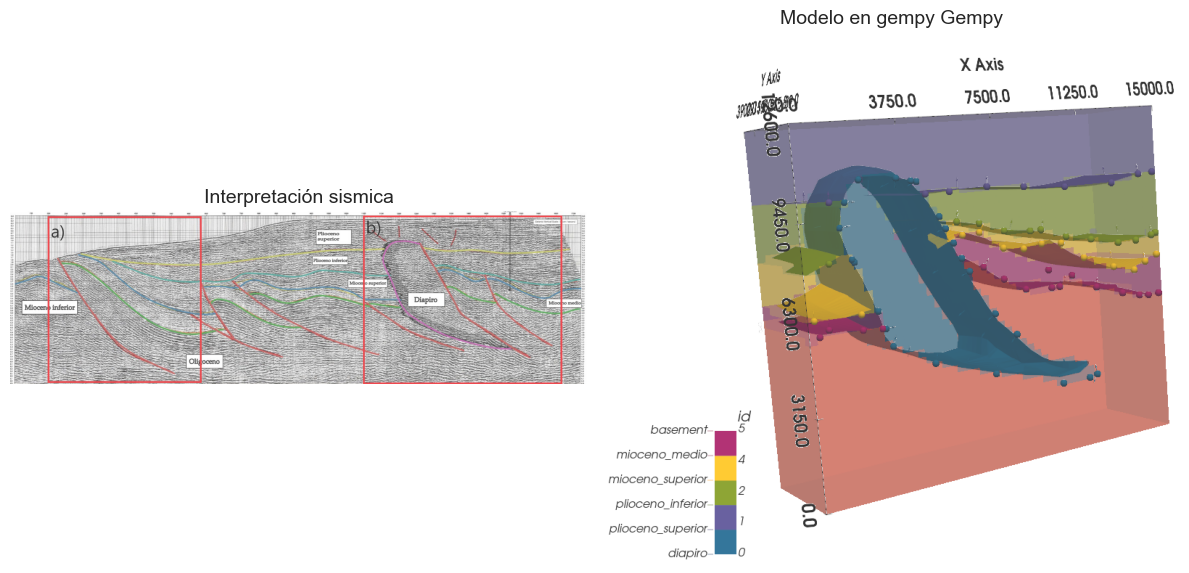

In [41]:
# Cargar las imágenes
img1 = mpimg.imread('G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\PICTURES\\ssj15interpretada.jpg')
img2 = mpimg.imread('G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\PICTURES\\gempy.PNG')  

# Crear una figura y dos subgráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 6))  # 1 fila, 2 columnas

# Mostrar la primera imagen
axes[0].imshow(img1, origin='upper', alpha=.8)
axes[0].axis('off')  # Opcional: quitar ejes
axes[0].set_title('Interpretación sismica', fontsize=14)  

# Mostrar la segunda imagen
axes[1].imshow(img2, origin='upper', alpha=.8)
axes[1].axis('off')  # Opcional: quitar ejes
axes[1].set_title('Modelo en gempy Gempy', fontsize=14)  

# Mostrar la figura
plt.tight_layout()
plt.show()

In [42]:
geo_model: gp.data.GeoModel = gp.create_geomodel(
    project_name='ssj15b',
    extent=[0, 15000.0000, 
            0, 3900.0000, 
            0, 12600.0000], #x,y,z
    resolution=[100, 100, 100],  # * Here we define the resolution of the voxels
    refinement=4,  # * Here we define the number of octree levels. If octree levels are defined, the resolution is ignored.
    importer_helper=gp.data.ImporterHelper(
        path_to_orientations="G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\POINTS\\model_orientations_SSJ_15b.csv",
        path_to_surface_points="G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\POINTS\\model_points_SSJ_15b.csv",
    )
)

gp.map_stack_to_surfaces(
    gempy_model=geo_model,
    mapping_object=  # TODO: This mapping I do not like it too much. We should be able to do it passing the data objects directly
    
    {
        #"Fault_Series9":'main_fault9',
        #"Fault_Series2":'main_fault2',
        #"Fault_Series3":'main_fault3',
        #"Fault_Series4":'main_fault4',
        #"Fault_Series5":'main_fault5',
        #"Fault_Series6":'main_fault6',
        #"Fault_Series7":'main_fault7',
        #"Fault_Series8":'main_fault8',
        #"Fault_Series9":'main_fault9',
        
        #"Fault_Series2":'main_fault2',
        #"Strat_Series1": ('diapiro'),
        #"Strat_Series2": ('secuenciaD','secuenciaB','secuenciaA'),
        "Strat_Series1": ('diapiro'),
        "Strat_Series2": ('plioceno_superior'),
        #"Strat_Series4": ('secuenciaB'),
        #"Strat_Series5": ('secuenciaA'),
        "Strat_Series3": ('plioceno_inferior'),
        "Strat_Series4": ('mioceno_superior'),
        "Strat_Series5": ('mioceno_medio')
        #"Strat_Series3": ('plioceno_superior')
        #"Strat_Series4": ('plioceno_superiorD'),
        #"Strat_Series5": ('plioceno_inferior'),
        #"Strat_Series5": ('mioceno_superior'),
        
        
        
        #"Fault_Series1":'main_fault1', #'mioceno_superior','mioceno_medio'),
    },
   
    set_series =True,
    remove_unused_series=True              
)



#gp.set_is_fault(
   #frame=geo_model.structural_frame,
   #fault_groups=["Fault_Series1" ]#, "Strat_Series2", "Strat_Series3", "Strat_Series4", "Strat_Series5"]# 'Fault_Series7', 'Fault_Series8']
                
#)




StructuralFrame(
	structural_groups=[
StructuralGroup(
	name=Strat_Series1,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=diapiro,
	color=#015482,
	is_active=True
)
]
),
StructuralGroup(
	name=Strat_Series2,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=plioceno_superior,
	color=#443988,
	is_active=True
)
]
),
StructuralGroup(
	name=Strat_Series3,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=plioceno_inferior,
	color=#728f02,
	is_active=True
)
]
),
StructuralGroup(
	name=Strat_Series4,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=mioceno_superior,
	color=#ffbe00,
	is_active=True
)
]
),
StructuralGroup(
	name=Strat_Series5,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=mioceno_medio,
	color=#9f0052,
	is_active=True
)
]
)
],
	fault_relations=
[[False, False, False, False, False],
 [False, False, False, False, False],
 [False, False, False, False, False],
 [False, False, False, False, False],
 [False, False, False, False, False]],

In [102]:
#geo_model.structural_frame.structural_elements[5].name = 'Mioceno_inferior'
#geo_model.structural_frame.structural_elements[5]

In [103]:
#gp.set_fault_relation(
    #frame=geo_model.structural_frame,
    #rel_matrix=np.array([
        #[0, 1, 1, 1, 1],  # Otra falla o capa
        #[1, 1, 1, 1, 1],  # Otra falla o capa
        #[1, 1, 1, 1, 1],  # Otra falla o capa
        #[1, 1, 1, 1, 1],  # Otra falla o capa
        #[0, 0, 1, 1, 1]   # "main_fault9" afecta solo mioceno medio y basamento
    #])
#)


In [104]:
#print(len(geo_model.structural_frame.structural_groups))

In [43]:
geo_model.input_transform.apply_anisotropy(gp.data.GlobalAnisotropy.NONE)

In [38]:
#geo_model.structural_frame.structural_elements

c:\Users\NICOLAS\.conda\envs\gempy\Lib\site-packages\gempy_viewer\API\_plot_2d_API.py:174: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  p.fig.show()


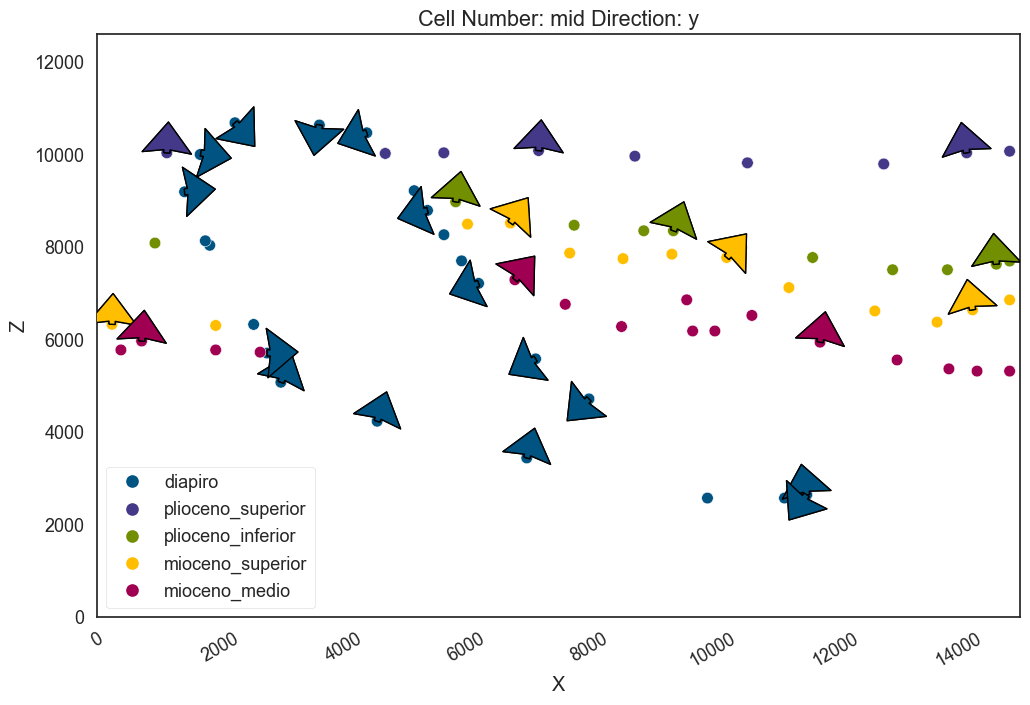

In [44]:
gpv.plot_2d(geo_model, cell_number='mid')

Modelo 2D

In [45]:
sol = gp.compute_model(geo_model)

Setting Backend To: AvailableBackends.numpy
Chunking done: 239 chunks
Chunking done: 65 chunks
Chunking done: 65 chunks
Chunking done: 79 chunks
Chunking done: 73 chunks
Chunking done: 7 chunks


c:\Users\NICOLAS\.conda\envs\gempy\Lib\site-packages\gempy_viewer\API\_plot_2d_API.py:174: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  p.fig.show()


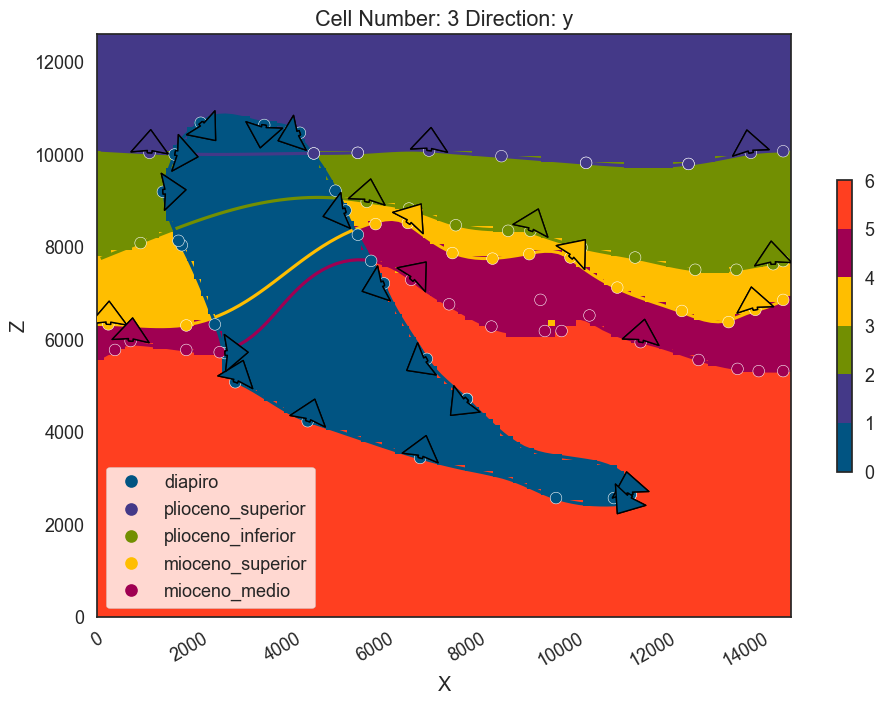

In [46]:
gpv.plot_2d(geo_model,show_boundaries=True,show_results=True,cell_number=3)

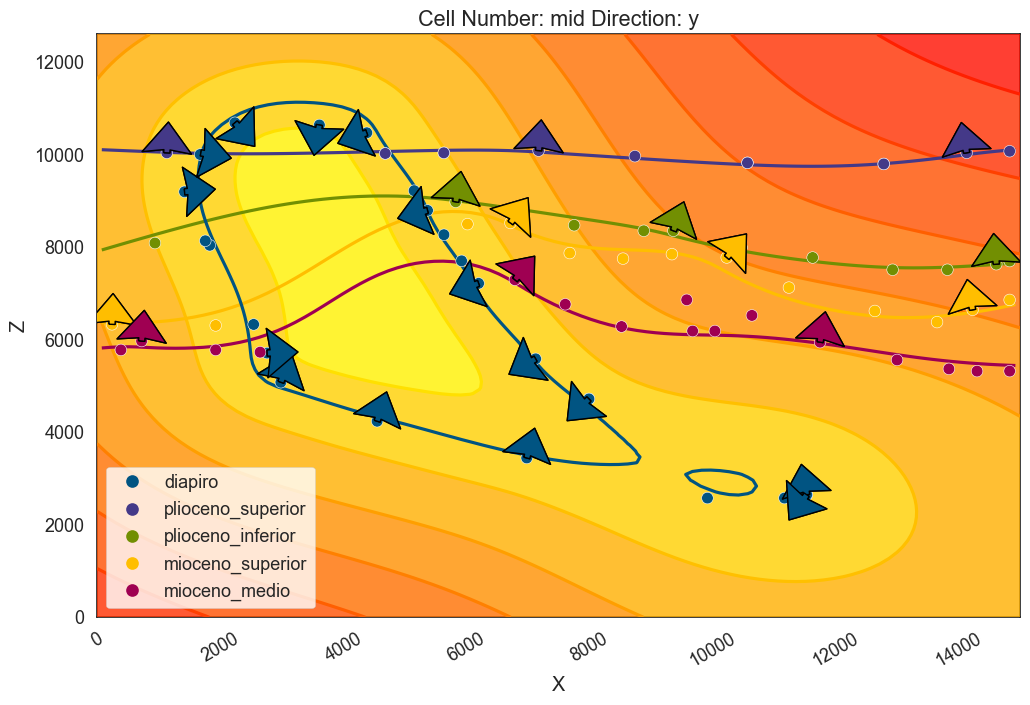

In [47]:
#campo escalar

p2d = gpv.plot_2d(
    model=geo_model,
    series_n=0,  # This will plot the scalar field used for the fault
    show_data=True,
    show_scalar=True,
    show_lith=False
)

plt.show()

Modelo 3D

In [48]:
gpv.plot_3d(geo_model, show_surfaces=True, image=False)

In [49]:
#gp.compute_model(geo_model)
#gpv.plot_3d(model=geo_model,
            #plotter_type='basic',
            #kwargs_plot_structured_grid={'opacity': .1},
            #show_surfaces=False,
            #show_topography=False,
            #show_data=True,
            #show_lith=True,
            #image=False,
            #legend=True,
            #ve=1.73            
            #)

velocidad de la onda p

In [50]:
grav_res = 20
X = np.linspace(0, 791, grav_res)
Y = np.linspace(-200, 200, grav_res)
Z = 0
xyz = np.meshgrid(X, Y, Z)
xy_ravel = np.vstack(list(map(np.ravel, xyz))).T
xy_ravel

array([[   0.        , -200.        ,    0.        ],
       [  41.63157895, -200.        ,    0.        ],
       [  83.26315789, -200.        ,    0.        ],
       ...,
       [ 707.73684211,  200.        ,    0.        ],
       [ 749.36842105,  200.        ,    0.        ],
       [ 791.        ,  200.        ,    0.        ]])

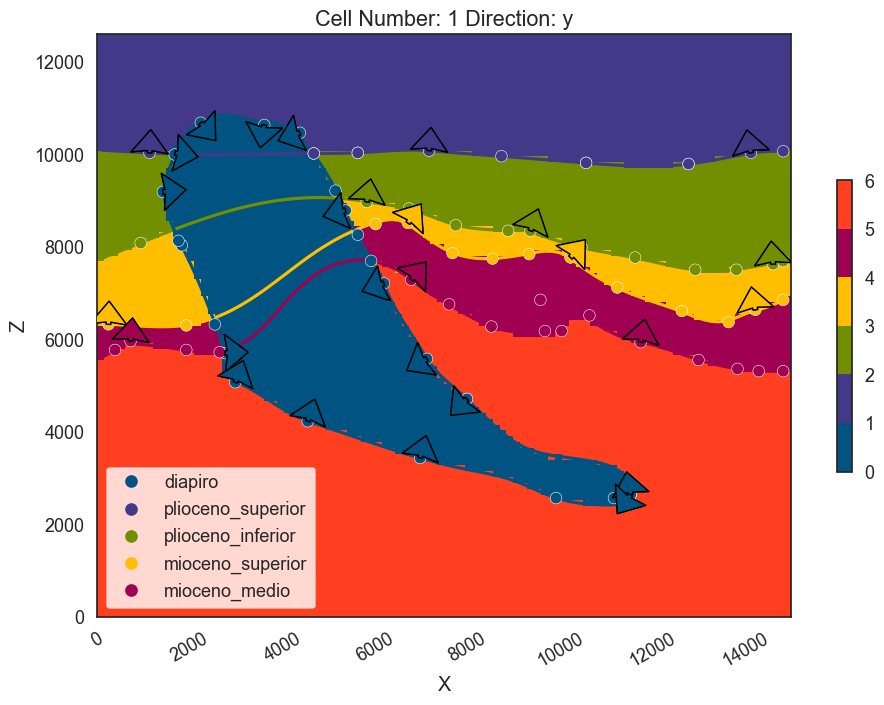

In [51]:
gpv.plot_2d(geo_model, direction='y', cell_number=1,show=False)
#plt.scatter(xy_ravel[:, 0], xy_ravel[:, 1], s=1)
plt.show()

In [52]:
gp.set_centered_grid(
    grid=geo_model.grid,
    centers=xy_ravel,
    resolution=np.array([10, 10, 15]),
    radius=np.array([50, 50, 50])
)

Active grids: GridTypes.DENSE|CENTERED|NONE


CenteredGrid(centers=array([[   0.        , -200.        ,    0.        ],
       [  41.63157895, -200.        ,    0.        ],
       [  83.26315789, -200.        ,    0.        ],
       ...,
       [ 707.73684211,  200.        ,    0.        ],
       [ 749.36842105,  200.        ,    0.        ],
       [ 791.        ,  200.        ,    0.        ]]), resolution=array([10, 10, 15]), radius=array([50, 50, 50]), kernel_grid_centers=array([[-50.        , -50.        ,  -3.        ],
       [-50.        , -50.        ,  -3.6       ],
       [-50.        , -50.        ,  -3.8336973 ],
       ...,
       [ 50.        ,  50.        , -34.07684808],
       [ 50.        ,  50.        , -46.18114038],
       [ 50.        ,  50.        , -63.        ]]), left_voxel_edges=array([[17.09430585, 17.09430585, -0.3       ],
       [17.09430585, 17.09430585, -0.3       ],
       [17.09430585, 17.09430585, -0.11684865],
       ...,
       [17.09430585, 17.09430585, -4.35564288],
       [17.09430585,

In [53]:
geo_model.grid.centered_grid.kernel_grid_centers

array([[-50.        , -50.        ,  -3.        ],
       [-50.        , -50.        ,  -3.6       ],
       [-50.        , -50.        ,  -3.8336973 ],
       ...,
       [ 50.        ,  50.        , -34.07684808],
       [ 50.        ,  50.        , -46.18114038],
       [ 50.        ,  50.        , -63.        ]])

In [54]:
array_sol = geo_model.solutions.raw_arrays.lith_block.reshape((100,100,100), order='F')

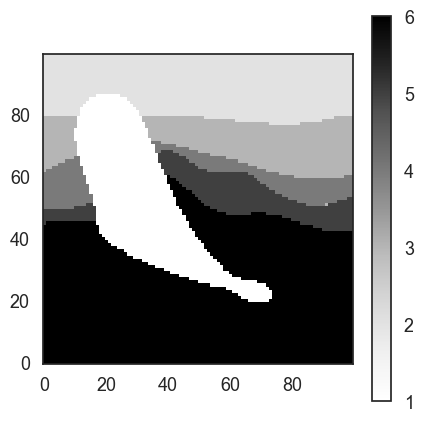

In [55]:
fig = plt.figure(figsize=(5,5))
plt.imshow(array_sol[:,25,:],origin='lower')
plt.colorbar()

In [27]:
geo_model.structural_frame.structural_elements[7]

Element(
	name=basement,
	color=#b271d0,
	is_active=True
)

In [56]:
#!pip install scikit-learn scikit-image
#from skimage.transform import rescale, resize, downscale_local_mean

array_sol2 = array_sol.copy()/1.

array_sol2[array_sol2==1]=2000
array_sol2[array_sol2==2]=2500
array_sol2[array_sol2==3]=2700
array_sol2[array_sol2==4]=3000
array_sol2[array_sol2==5]=3500
array_sol2[array_sol2==6]=3800
#array_sol2[array_sol2==10]=5200
#array_sol2[array_sol2==11]=5300

vmodel = array_sol2[:,25,:].copy()
vmodel = np.flip(vmodel,axis=0)

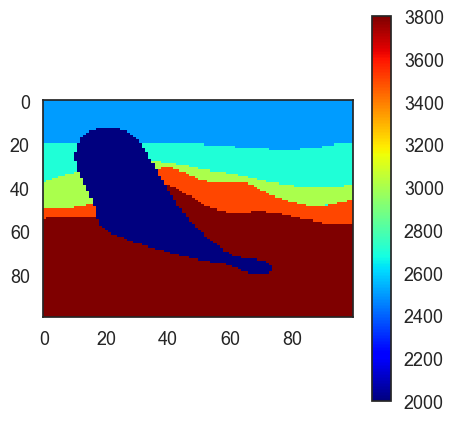

In [57]:
plt.figure(figsize=(5,5))
plt.imshow(vmodel,aspect=0.7,interpolation='nearest',cmap='jet')
plt.colorbar()

In [58]:
nx = 100
nz = 100

fx = 0
fz = -200

dx = np.abs(791)//nx
dz = np.abs(400)//nz

x_pos = np.arange(nx)*dx + fx
z_pos = -np.arange(nz)*dz +  fz

print('nx: ', nx)
print('nz: ', nz)
print('dx: ', dx)
print('dz: ', dz)

nx:  100
nz:  100
dx:  7
dz:  4


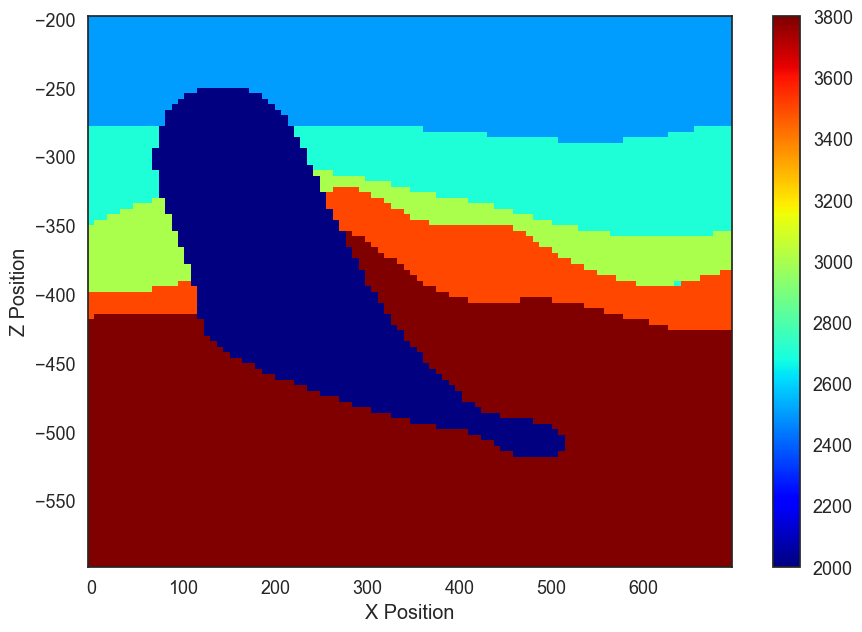

In [59]:
plt.pcolormesh(x_pos, z_pos, vmodel, cmap='jet', shading='auto')
plt.colorbar()
plt.xlabel('X Position')
plt.ylabel('Z Position')
plt.show()

Export .npyb

In [60]:
np.save('G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\vpmodel_gempy.npy',vmodel)

Exportar .picckle

In [61]:
filename = 'G:\\SHAIRETH\\Auxiliatura P3925\\ssj_model15B\\SSJ_15B.pickle'

# Abre el archivo en modo escritura binaria y guarda el modelo
with open(filename, 'wb') as file:
    pickle.dump(geo_model, file)

print(f"Modelo exportado exitosamente en {filename}")

Modelo exportado exitosamente en G:\SHAIRETH\Auxiliatura P3925\ssj_model15B\SSJ_15B.pickle


In [62]:
#cargar el modelo  .pickle
with open('SSJ_15B.pickle', 'rb') as file:
    geo_model1 = pickle.load(file)

print("Modelo cargado exitosamente")

Modelo cargado exitosamente


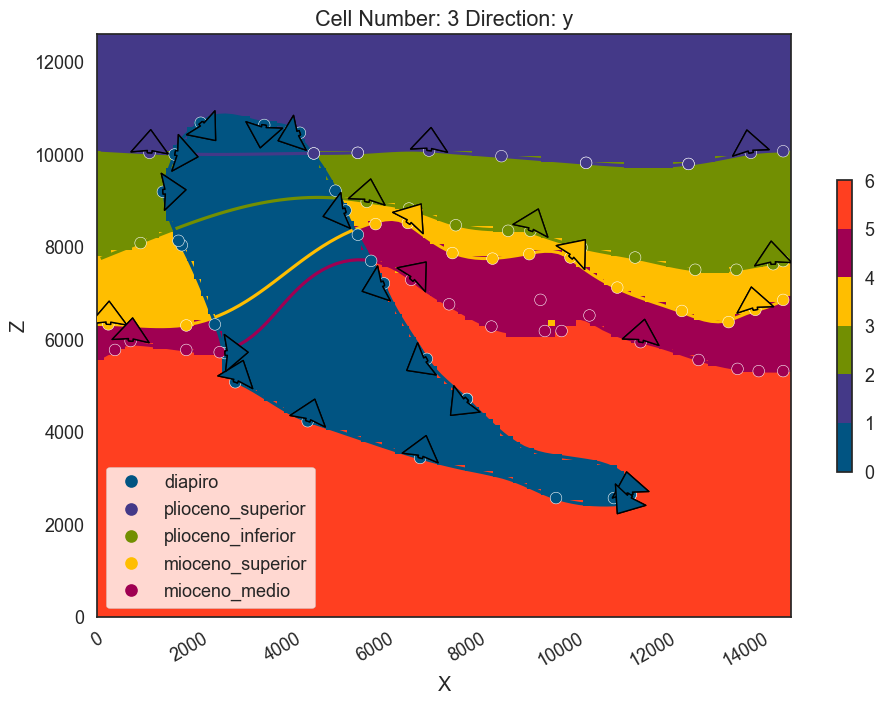

In [63]:
gpv.plot_2d(geo_model1,show_boundaries=True,show_results=True,cell_number=3)

In [39]:
gpv.plot_3d(geo_model1, show_surfaces=True, image=False)